# Section 1 — Import Libraries

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import cv2
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report)
import seaborn as sns

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [2]:
# # ============================================================
# # Project Directory
# # ============================================================
  
PROJECT_DIR = "C:/Users/aurna/Documents/brac_thesis"

In [3]:
METADATA_DIR = os.path.join(
    PROJECT_DIR,
    "metadata"
)

In [4]:
# # ============================================================
# # Dataset Files
# # ============================================================

TRAIN_CSV = os.path.join(
    METADATA_DIR,
    "train.csv"
)

VALIDATION_CSV = os.path.join(
    METADATA_DIR,
    "validation.csv"
)

TEST_CSV = os.path.join(
    METADATA_DIR,
    "test.csv"
)

METADATA_PATH = os.path.join(
    METADATA_DIR,
    "metadata.json"
)

print("Dataset Paths Ready")

Dataset Paths Ready


In [5]:
# ============================================================
# Load Metadata
# ============================================================

with open(

    METADATA_PATH,

    "r"

) as file:

    metadata = json.load(

        file

    )

IMAGE_HEIGHT = metadata["image_height"]

IMAGE_WIDTH = metadata["image_width"]

CHANNELS = metadata["channels"]

NUM_CLASSES = metadata["total_labels"]

CLASS_NAMES = metadata["labels"]

LABEL_TO_INDEX = metadata["label_to_index"]

INDEX_TO_LABEL = metadata["index_to_label"]

print("Metadata Loaded Successfully")

Metadata Loaded Successfully


In [6]:
# ============================================================
# Model Paths
# ============================================================

MODELS_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

MODEL_PATH = os.path.join(
    MODELS_DIR,
    "skin_condition_identifier.keras"
)

HISTORY_PATH = os.path.join(
    MODELS_DIR,
    "training_history.json"
)

print("Model Paths Ready")

Model Paths Ready


In [7]:
# ============================================================
# Load Trained Model
# ============================================================

model = keras.models.load_model(

    MODEL_PATH

)

print("Model Loaded Successfully")

Model Loaded Successfully


In [8]:
# ============================================================
# Model Information
# ============================================================

print("=" * 70)

print("MODEL INFORMATION")

print("=" * 70)

print(f"Model Name      : {model.name}")

print(f"Input Shape     : {model.input_shape}")

print(f"Output Shape    : {model.output_shape}")

print(f"Total Labels    : {NUM_CLASSES}")

MODEL INFORMATION
Model Name      : Model_Eczema
Input Shape     : (None, 224, 224, 3)
Output Shape    : (None, 12)
Total Labels    : 12


# Section 2 — Load Test Image

In [9]:
# ============================================================
# Section 2 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

Total Test Images : 1063


In [10]:
# # ============================================================
# # Select Image
# # ============================================================

# IMAGE_PATH = "H:/Aurnab/Thesis/from_chatgpt6/Processed_Dataset/Images/Acne_Moderate_acne_mod_359.jpg"
# TRUE_LABEL = "Acne_Moderate"
IMAGE_PATH = None
if IMAGE_PATH is None:

    sample = test_df.sample(

        n=1,

        random_state=None

    ).iloc[0]

    IMAGE_PATH = sample["filepath"]

    TRUE_LABEL = sample["label"]

else:

    TRUE_LABEL = "Unknown"

print(

    "Image Selected Successfully"

)

Image Selected Successfully


In [11]:
# ============================================================
# Load Image
# ============================================================

image = tf.io.read_file(

    IMAGE_PATH

)

image = tf.io.decode_image(

    image,

    channels=CHANNELS,

    expand_animations=False

)

image.set_shape(

    [

        IMAGE_HEIGHT,

        IMAGE_WIDTH,

        CHANNELS

    ]

)

image = tf.cast(

    image,

    tf.float32

)

input_tensor = tf.expand_dims(

    image,

    axis=0

)

print(

    "Image Loaded Successfully"

)

Image Loaded Successfully


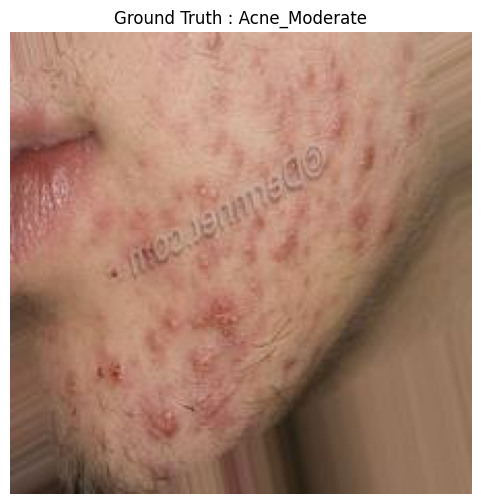

In [12]:
# ============================================================
# Display Image
# ============================================================

plt.figure(

    figsize=(6,6)

)

plt.imshow(

    tf.cast(

        image,

        tf.uint8

    )

)

plt.title(

    f"Ground Truth : {TRUE_LABEL}"

)

plt.axis(

    "off"

)

plt.show()

In [13]:
# ============================================================
# Image Information
# ============================================================

print("=" * 70)

print("IMAGE INFORMATION")

print("=" * 70)

print(f"Path        : {IMAGE_PATH}")

print(f"True Label  : {TRUE_LABEL}")

print(f"Shape       : {image.shape}")

IMAGE INFORMATION
Path        : C:/Users/aurna/Documents/brac_thesis/dataset/test/acne/moderate/acne_moderate_095.jpeg
True Label  : Acne_Moderate
Shape       : (224, 224, 3)


# Section 3 — Predict All Label Probabilities

In [14]:
# ============================================================
# Section 3 : Predict
# ============================================================

predictions = model.predict(

    input_tensor,

    verbose=1

)

probabilities = predictions[0]

print("Prediction Completed Successfully")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Prediction Completed Successfully


In [15]:
# ============================================================
# Prediction Table
# ============================================================

prediction_df = pd.DataFrame(

    {

        "Label": CLASS_NAMES,

        "Probability": probabilities

    }

)

prediction_df["Probability (%)"] = (

    prediction_df["Probability"] * 100

)

prediction_df = prediction_df.sort_values(

    by="Probability",

    ascending=False

).reset_index(

    drop=True

)

print("Prediction Table Created Successfully")

Prediction Table Created Successfully


In [16]:
# ============================================================
# Prediction Result
# ============================================================

print("=" * 70)

print("PREDICTED PROBABILITIES")

print("=" * 70)

display(

    prediction_df
)

PREDICTED PROBABILITIES


,Label,Probability,Probability (%)
0,Acne_Severe,9.203459e-01,92.034592
1,Acne_Moderate,7.802223e-02,7.802223
2,Acne_Mild,1.228019e-03,0.122802
3,Eczema_Moderate,2.016464e-04,0.020165
4,Eczema_Severe,1.972064e-04,0.019721
5,Eczema_Mild,1.732373e-06,0.000173
6,Burn_Moderate,1.365569e-06,0.000137
7,Normal_Dry,1.187779e-06,0.000119
8,Burn_Severe,2.164788e-07,0.000022
9,Normal_Normal,1.699659e-07,0.000017


In [17]:
# ============================================================
# Organized Prediction Results
# ============================================================

prediction_dict = {}

# Build dictionary dynamically
for label, probability in zip(

    CLASS_NAMES,

    probabilities

):

    disease, severity = label.split("_", 1)

    if disease not in prediction_dict:

        prediction_dict[disease] = {}

    prediction_dict[disease][severity] = probability * 100

print("=" * 70)

print("PREDICTION RESULTS")

print("=" * 70)

for disease in sorted(prediction_dict.keys()):

    print()

    print(disease)

    print("-" * 40)

    severities = prediction_dict[disease]

    for severity in sorted(severities.keys()):

        print(

            f"{severity:<15}: "

            f"{severities[severity]:6.2f}%"

        )

PREDICTION RESULTS

Acne
----------------------------------------
Mild           :   0.12%
Moderate       :   7.80%
Severe         :  92.03%

Burn
----------------------------------------
Mild           :   0.00%
Moderate       :   0.00%
Severe         :   0.00%

Eczema
----------------------------------------
Mild           :   0.00%
Moderate       :   0.02%
Severe         :   0.02%

Normal
----------------------------------------
Dry            :   0.00%
Normal         :   0.00%
Oily           :   0.00%


In [18]:
# ============================================================
# Top Prediction
# ============================================================

predicted_label = prediction_df.loc[

    0,

    "Label"

]

predicted_probability = prediction_df.loc[

    0,

    "Probability (%)"

]

print("=" * 70)

print("TOP PREDICTION")

print("=" * 70)

print(f"Predicted Label : {predicted_label}")

print(f"Confidence      : {predicted_probability:.2f}%")

TOP PREDICTION
Predicted Label : Acne_Severe
Confidence      : 92.03%


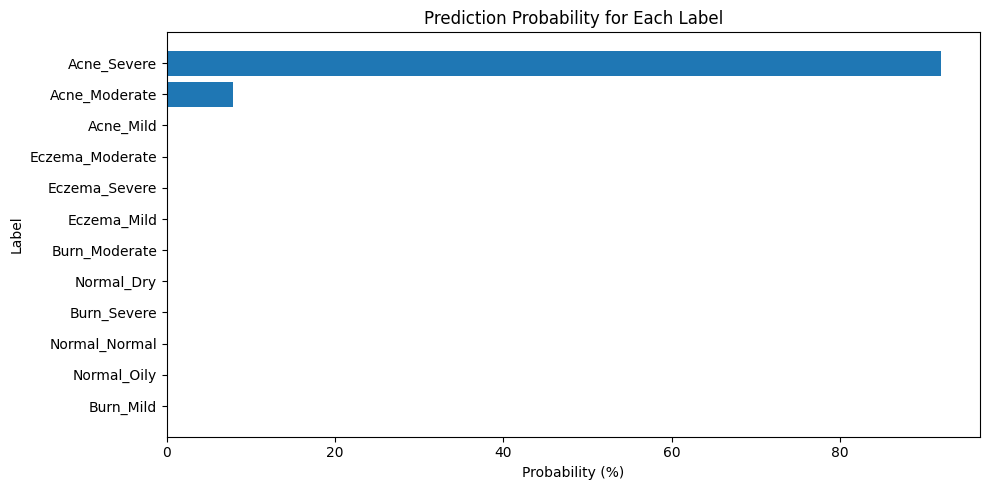

In [19]:
# ============================================================
# Probability Distribution
# ============================================================

plt.figure(

    figsize=(10,5)

)

plt.barh(

    prediction_df["Label"],

    prediction_df["Probability (%)"]

)

plt.xlabel(

    "Probability (%)"

)

plt.ylabel(

    "Label"

)

plt.title(

    "Prediction Probability for Each Label"

)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

# Section 4 - Visualization with LIME

## 4.1 - Import the required libraries:

In [21]:
# ============================================================
# LIME Imports
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from lime.lime_image import LimeImageExplainer
from skimage.segmentation import slic, mark_boundaries

print("LIME Libraries Imported Successfully")

LIME Libraries Imported Successfully


## 4.2 - Prepare the LIME Prediction Function

In [22]:
# ============================================================
# LIME Prediction Function
# ============================================================

# Determine the input scale used by the model
input_max_value = float(
    tf.reduce_max(input_tensor).numpy()
)

MODEL_INPUT_SCALE = (
    1.0 if input_max_value <= 1.5 else 255.0
)


def lime_predict(images):

    # Convert images to NumPy array
    images = np.asarray(
        images,
        dtype=np.float32
    )

    # Match the model's original input scale
    if MODEL_INPUT_SCALE == 1.0:

        images = images / 255.0

    # Obtain predictions
    predictions = model.predict(
        images,
        verbose=1
    )

    return predictions


print("LIME Prediction Function Ready")

LIME Prediction Function Ready


## 4.3 - Prepare the Input Image and Superpixels

In [23]:
# ============================================================
# Prepare LIME Input Image
# ============================================================

# Extract image from input tensor
lime_input_image = input_tensor[0].numpy()

# Convert to uint8 RGB for LIME
lime_input_image = np.clip(
    lime_input_image,
    0,
    255
)

if MODEL_INPUT_SCALE == 1.0:

    lime_input_image = lime_input_image * 255.0

lime_input_image = np.uint8(
    lime_input_image
)


# ------------------------------------------------------------
# Generate Superpixels
# ------------------------------------------------------------

segments = slic(
    lime_input_image,
    n_segments=100,
    compactness=10,
    sigma=1,
    start_label=1,
    channel_axis=-1
)


# ------------------------------------------------------------
# Initialize LIME Explainer
# ------------------------------------------------------------

explainer = LimeImageExplainer(
    random_state=42
)


print(
    "LIME Input Image Shape:",
    lime_input_image.shape
)

print(
    "Number of Superpixels:",
    len(np.unique(segments))
)

print("LIME Explainer Initialized Successfully")

LIME Input Image Shape: (224, 224, 3)
Number of Superpixels: 99
LIME Explainer Initialized Successfully


In [28]:
# ============================================================
# Prepare Prediction Probabilities for LIME
# ============================================================

lime_probabilities = np.asarray(
    probabilities
).reshape(-1)

print(
    "Number of Prediction Probabilities:",
    len(lime_probabilities)
)

print(
    "Number of Classes:",
    NUM_CLASSES
)

assert len(lime_probabilities) == NUM_CLASSES, \
    "Prediction probabilities do not match the number of classes."

print("LIME Prediction Probabilities Ready")

Number of Prediction Probabilities: 12
Number of Classes: 12
LIME Prediction Probabilities Ready


## 4.4 - Generate LIME Explanation for All Classes

In [29]:
# ============================================================
# Section 4 : Generate MobileNetV3Small LIME Explanations
# ============================================================

lime_results = []

# ------------------------------------------------------------
# LIME Configuration
# ------------------------------------------------------------

NUM_SAMPLES = 500

NUM_FEATURES = 10

BATCH_SIZE = 32


# ------------------------------------------------------------
# Generate Explanations for All Classes
# ------------------------------------------------------------

for class_index in range(NUM_CLASSES):

    print(
        f"\nGenerating LIME explanation for:",
        CLASS_NAMES[class_index]
    )

    # --------------------------------------------------------
    # Generate LIME Explanation
    # --------------------------------------------------------

    explanation = explainer.explain_instance(

        lime_input_image,

        classifier_fn=lime_predict,

        labels=(class_index,),

        top_labels=None,

        hide_color=0,

        num_samples=NUM_SAMPLES,

        batch_size=BATCH_SIZE,

        segmentation_fn=lambda image: segments

    )

    # --------------------------------------------------------
    # Verify Requested Class
    # --------------------------------------------------------

    if class_index not in explanation.local_exp:

        raise ValueError(
            f"Class {class_index} was not found in LIME explanation."
        )

    # --------------------------------------------------------
    # Extract Important Superpixels
    # --------------------------------------------------------

    temp, mask = explanation.get_image_and_mask(

        label=class_index,

        positive_only=False,

        num_features=NUM_FEATURES,

        hide_rest=False

    )

    # --------------------------------------------------------
    # Create Visualization
    # --------------------------------------------------------

    visualization = temp.astype(
        np.float32
    ).copy()

    positive_mask = mask > 0

    negative_mask = mask < 0

    # Positive contribution: Green
    visualization[positive_mask] = (

        visualization[positive_mask] * 0.5

        + np.array([0, 255, 0]) * 0.5

    )

    # Negative contribution: Red
    visualization[negative_mask] = (

        visualization[negative_mask] * 0.5

        + np.array([255, 0, 0]) * 0.5

    )

    visualization = np.uint8(
        np.clip(visualization, 0, 255)
    )

    # --------------------------------------------------------
    # Add Superpixel Boundaries
    # --------------------------------------------------------

    visualization = mark_boundaries(

        visualization,

        segments,

        color=(1, 1, 0),

        mode="thick"

    )

    # --------------------------------------------------------
    # Get Prediction Probability
    # --------------------------------------------------------

    probability = lime_probabilities[class_index] * 100

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    lime_results.append({

        "label": CLASS_NAMES[class_index],

        "probability": probability,

        "visualization": visualization,

        "explanation": explanation,

        "mask": mask

    })


print(
    "\nMobileNetV3Small LIME Explanations Generated Successfully"
)


Generating LIME explanation for: Acne_Mild


  0%|          | 0/500 [00:00<?, ?it/s]


Generating LIME explanation for: Acne_Moderate


  0%|          | 0/500 [00:00<?, ?it/s]


Generating LIME explanation for: Acne_Severe


  0%|          | 0/500 [00:00<?, ?it/s]

... (15 outputs left out)

  0%|          | 0/500 [00:00<?, ?it/s]


Generating LIME explanation for: Normal_Oily


  0%|          | 0/500 [00:00<?, ?it/s]


MobileNetV3Small LIME Explanations Generated Successfully


## 4.5 - Sort LIME Results

In [30]:
# ============================================================
# Section 5 : Sort LIME Results
# ============================================================

# Ensure probabilities have a one-dimensional shape
lime_probabilities = np.asarray(
    probabilities
).reshape(-1)

# Sort LIME results
lime_results = sorted(

    lime_results,

    key=lambda item: item["probability"],

    reverse=True

)

print("LIME Results Sorted Successfully")

LIME Results Sorted Successfully


## 4.6 - Display MobileNetV3Small LIME Visualization

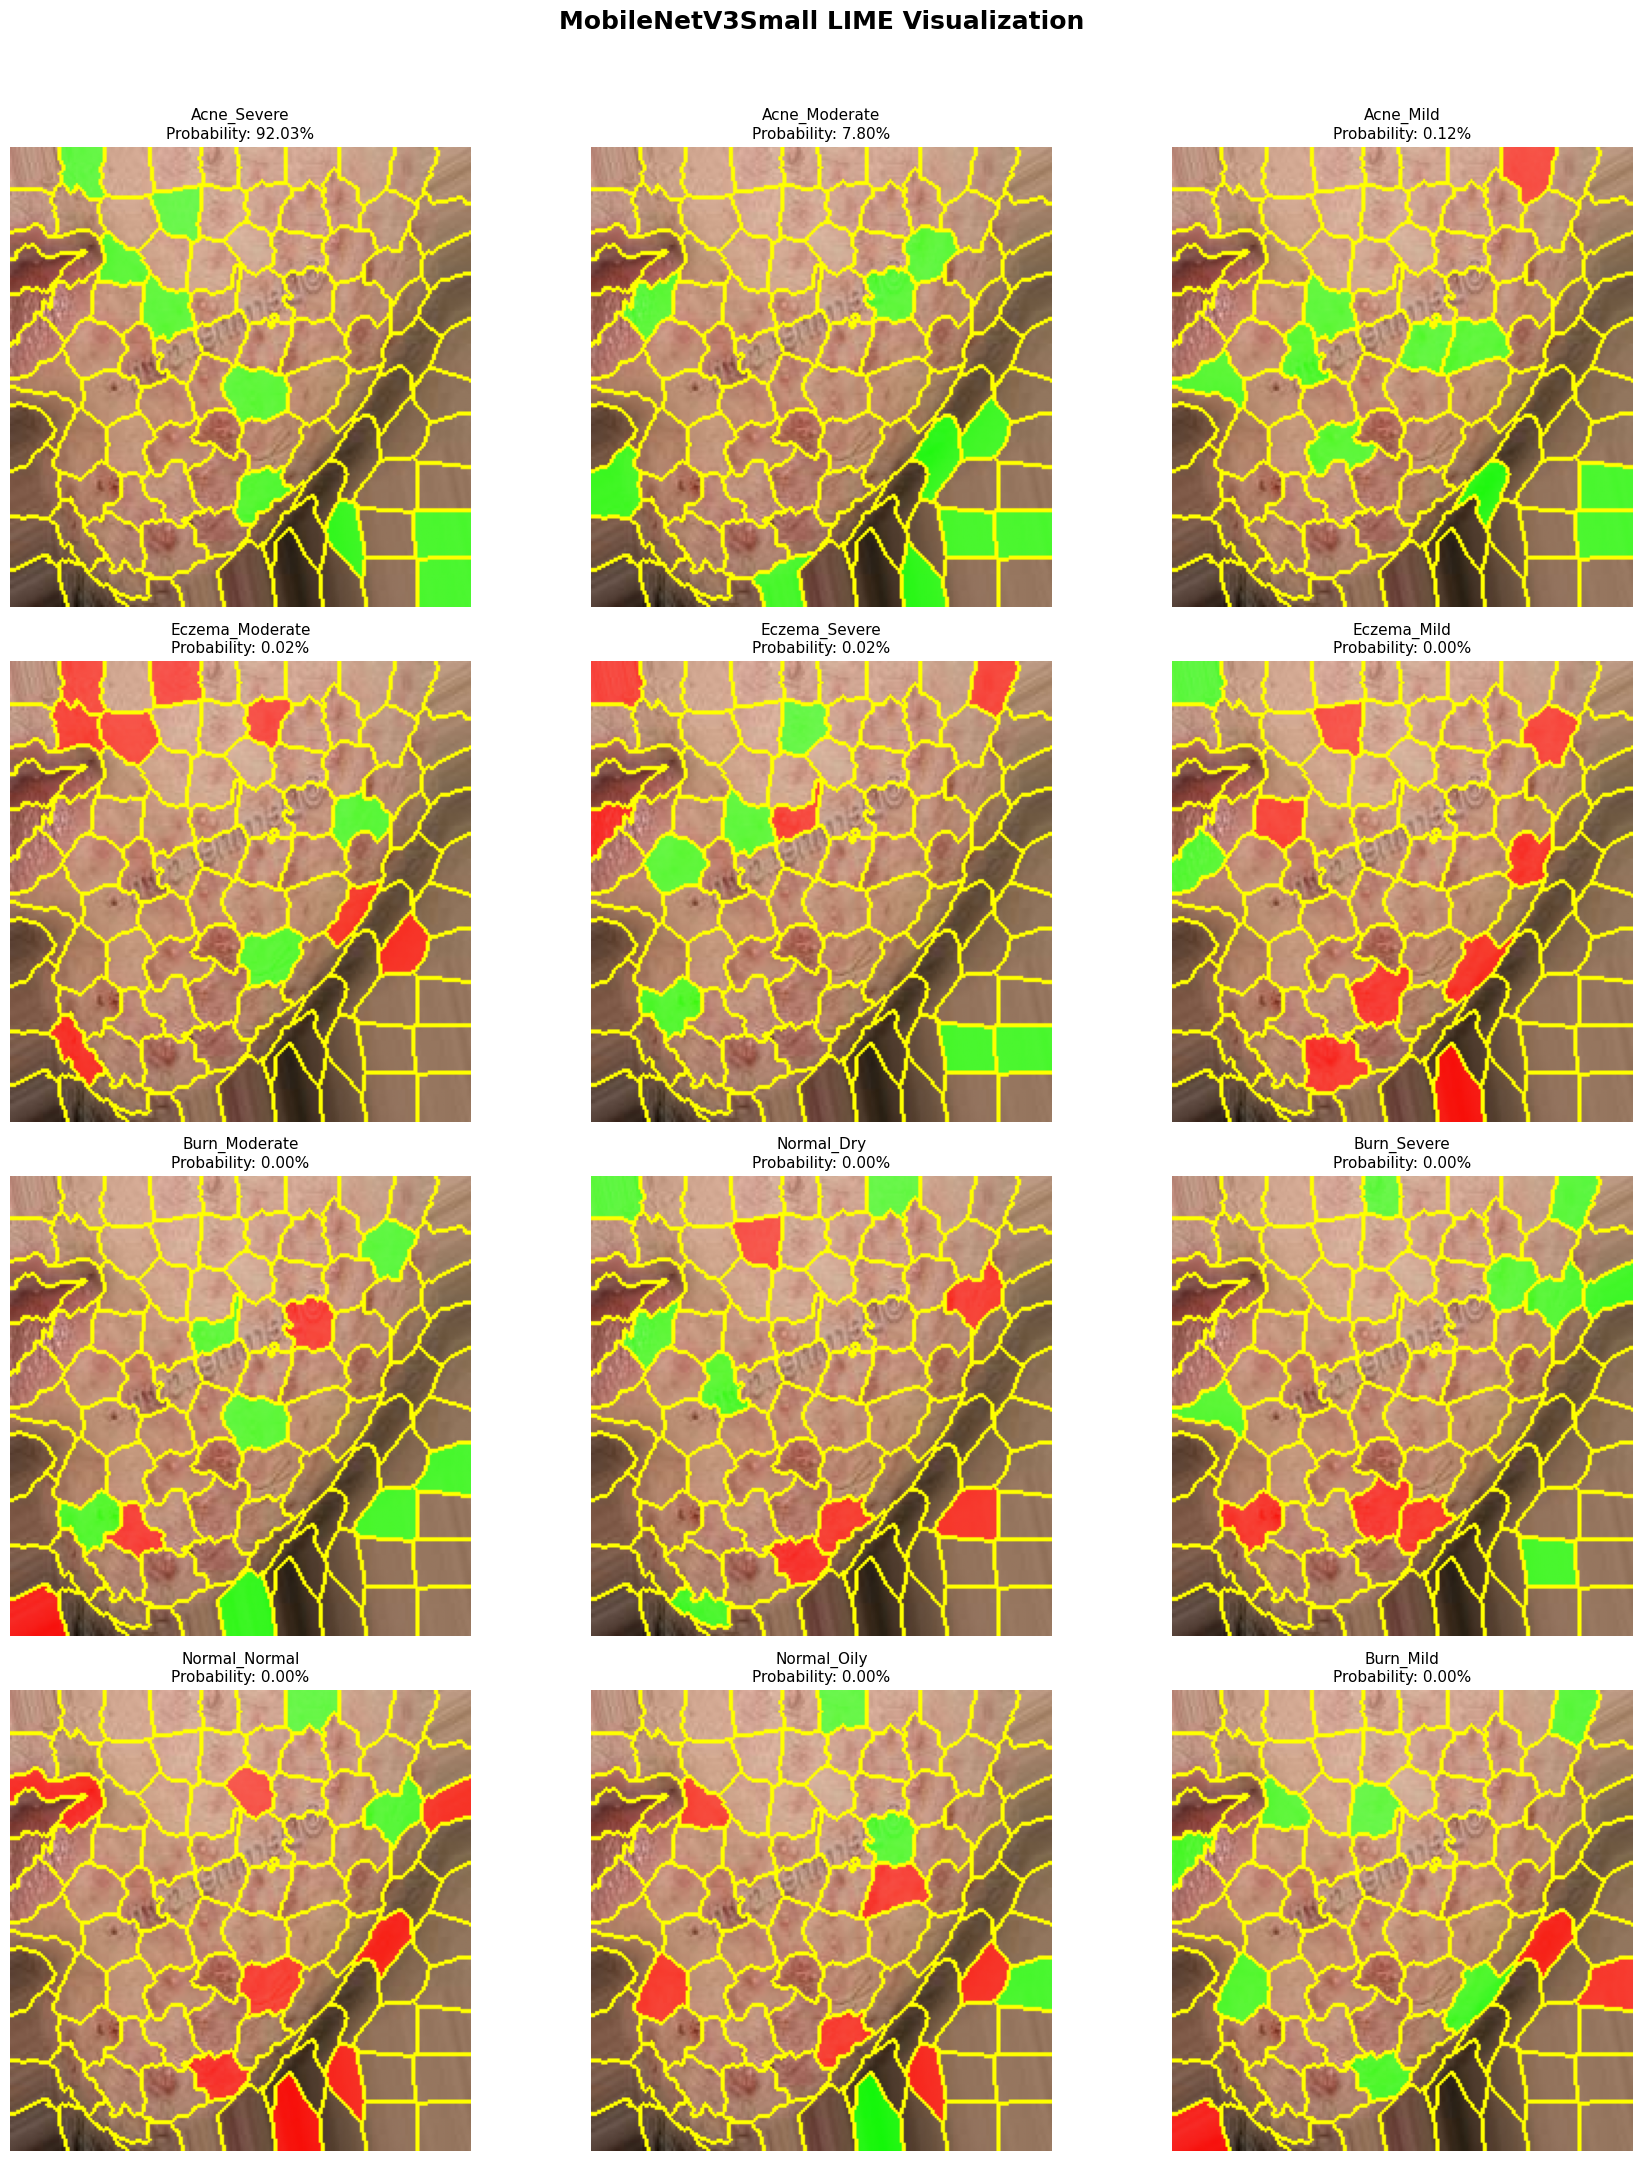

MobileNetV3Small LIME Visualization Completed


In [32]:
# ============================================================
# Section 6 : Display MobileNetV3Small LIME
# ============================================================

# Create a single figure with 12 subplots
fig, axes = plt.subplots(
    4,
    3,
    figsize=(18, 22)
)

# Flatten axes for easy iteration
axes = axes.flatten()

# ------------------------------------------------------------
# Display LIME Results
# ------------------------------------------------------------

for i, result in enumerate(lime_results):

    # Display LIME visualization
    axes[i].imshow(
        result["visualization"]
    )

    axes[i].set_title(

        f'{result["label"]}\n'
        f'Probability: {result["probability"]:.2f}%',

        fontsize=11

    )

    axes[i].axis("off")


# ------------------------------------------------------------
# Hide Unused Subplots
# ------------------------------------------------------------

for j in range(len(lime_results), len(axes)):

    axes[j].axis("off")


# ------------------------------------------------------------
# Overall Figure Title
# ------------------------------------------------------------

fig.suptitle(

    "MobileNetV3Small LIME Visualization",

    fontsize=18,

    fontweight="bold"

)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


# ------------------------------------------------------------
# Save Visualization
# ------------------------------------------------------------

os.makedirs(

    os.path.join(PROJECT_DIR, "results"),

    exist_ok=True

)

plt.savefig(

    os.path.join(
        PROJECT_DIR,
        "results",
        "lime.png"
    ),

    dpi=300,

    bbox_inches="tight"

)


plt.show()


print(
    "MobileNetV3Small LIME Visualization Completed"
)

# Section 5 — Evaluate Model

In [27]:
# ============================================================
# Section 6 : Load Test Dataset
# ============================================================

test_df = pd.read_csv(

    TEST_CSV

)

print(

    f"Total Test Images : {len(test_df)}"

)

Total Test Images : 1063


In [28]:
# ============================================================
# Image Loading Function
# ============================================================

def load_image(

    image_path,

    label

):

    image = tf.io.read_file(

        image_path

    )

    image = tf.io.decode_image(

        image,

        channels=CHANNELS,

        expand_animations=False

    )

    image.set_shape(

        [

            IMAGE_HEIGHT,

            IMAGE_WIDTH,

            CHANNELS

        ]

    )

    image = tf.cast(

        image,

        tf.float32

    )

    label = tf.one_hot(

        label,

        depth=NUM_CLASSES,

        dtype=tf.float32

    )

    return image, label

print("Image Loader Ready")

Image Loader Ready


In [29]:
# ============================================================
# Prepare Test Dataset
# ============================================================

test_image_paths = test_df["filepath"].values

test_labels = test_df["label"].map(

    LABEL_TO_INDEX

).values

test_dataset = tf.data.Dataset.from_tensor_slices(

    (

        test_image_paths,

        test_labels

    )

)

test_dataset = test_dataset.map(

    load_image,

    num_parallel_calls=tf.data.AUTOTUNE

)

test_dataset = test_dataset.batch(

    32

).prefetch(

    tf.data.AUTOTUNE

)

print("Test Dataset Ready")

Test Dataset Ready


In [30]:
# ============================================================
# Predict Test Dataset
# ============================================================

predictions = model.predict(

    test_dataset,

    verbose=1

)

predicted_labels = np.argmax(

    predictions,

    axis=1

)

true_labels = np.argmax(

    np.concatenate(

        [

            labels.numpy()

            for _, labels in test_dataset

        ],

        axis=0

    ),

    axis=1

)

print("Prediction Completed Successfully")

34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 183ms/step
Prediction Completed Successfully


In [31]:
# ============================================================
# Evaluation Metrics
# ============================================================

accuracy = accuracy_score(

    true_labels,

    predicted_labels

)

precision = precision_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

recall = recall_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

f1 = f1_score(

    true_labels,

    predicted_labels,

    average="weighted"

)

print("=" * 70)

print("MODEL PERFORMANCE")

print("=" * 70)

print(f"Accuracy  : {accuracy:.4f}")

print(f"Precision : {precision:.4f}")

print(f"Recall    : {recall:.4f}")

print(f"F1 Score  : {f1:.4f}")

MODEL PERFORMANCE
Accuracy  : 0.6566
Precision : 0.6597
Recall    : 0.6566
F1 Score  : 0.6505


In [32]:
# ============================================================
# Classification Report
# ============================================================

report = classification_report(

    true_labels,

    predicted_labels,

    target_names=CLASS_NAMES,

    output_dict=True

)

print(report)

{'Acne_Mild': {'precision': 0.6442307692307693, 'recall': 0.6767676767676768, 'f1-score': 0.6600985221674877, 'support': 99.0}, 'Acne_Moderate': {'precision': 0.6666666666666666, 'recall': 0.40404040404040403, 'f1-score': 0.5031446540880503, 'support': 99.0}, 'Acne_Severe': {'precision': 0.6875, 'recall': 0.7777777777777778, 'f1-score': 0.7298578199052133, 'support': 99.0}, 'Burn_Mild': {'precision': 0.8129496402877698, 'recall': 0.7687074829931972, 'f1-score': 0.7902097902097902, 'support': 147.0}, 'Burn_Moderate': {'precision': 0.7218543046357616, 'recall': 0.7956204379562044, 'f1-score': 0.7569444444444444, 'support': 137.0}, 'Burn_Severe': {'precision': 0.8222222222222222, 'recall': 0.7254901960784313, 'f1-score': 0.7708333333333334, 'support': 51.0}, 'Eczema_Mild': {'precision': 0.5454545454545454, 'recall': 0.7878787878787878, 'f1-score': 0.6446280991735537, 'support': 99.0}, 'Eczema_Moderate': {'precision': 0.5230769230769231, 'recall': 0.3434343434343434, 'f1-score': 0.41463414

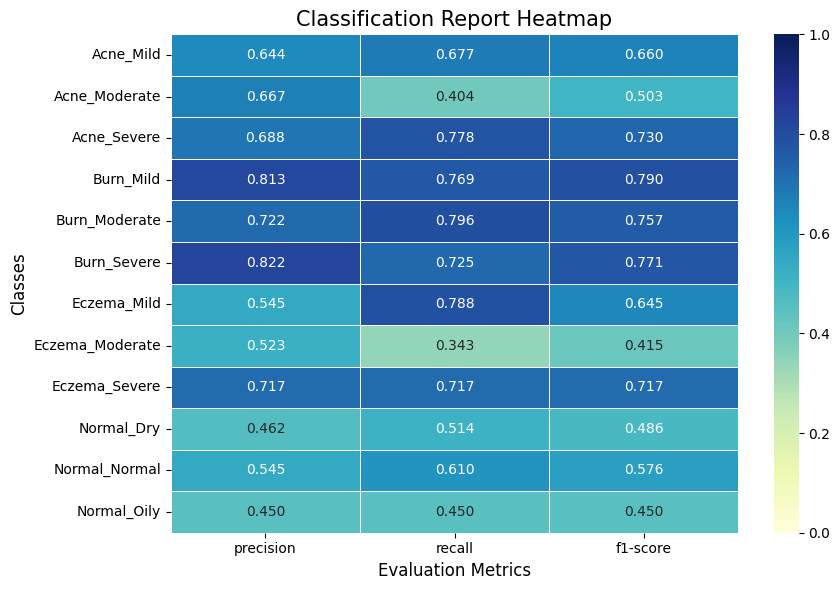

In [33]:
# Convert report into DataFrame
df = pd.DataFrame(report).transpose()

# Select class-wise metrics
df_plot = df.loc[CLASS_NAMES, ['precision', 'recall', 'f1-score']]

# Plot heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    df_plot,
    annot=True,
    cmap='YlGnBu',
    fmt='.3f',
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title('Classification Report Heatmap', fontsize=15)
plt.xlabel('Evaluation Metrics', fontsize=12)
plt.ylabel('Classes', fontsize=12)

plt.tight_layout()

# Save figure
plt.savefig(f'{PROJECT_DIR}/results/classification_report.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

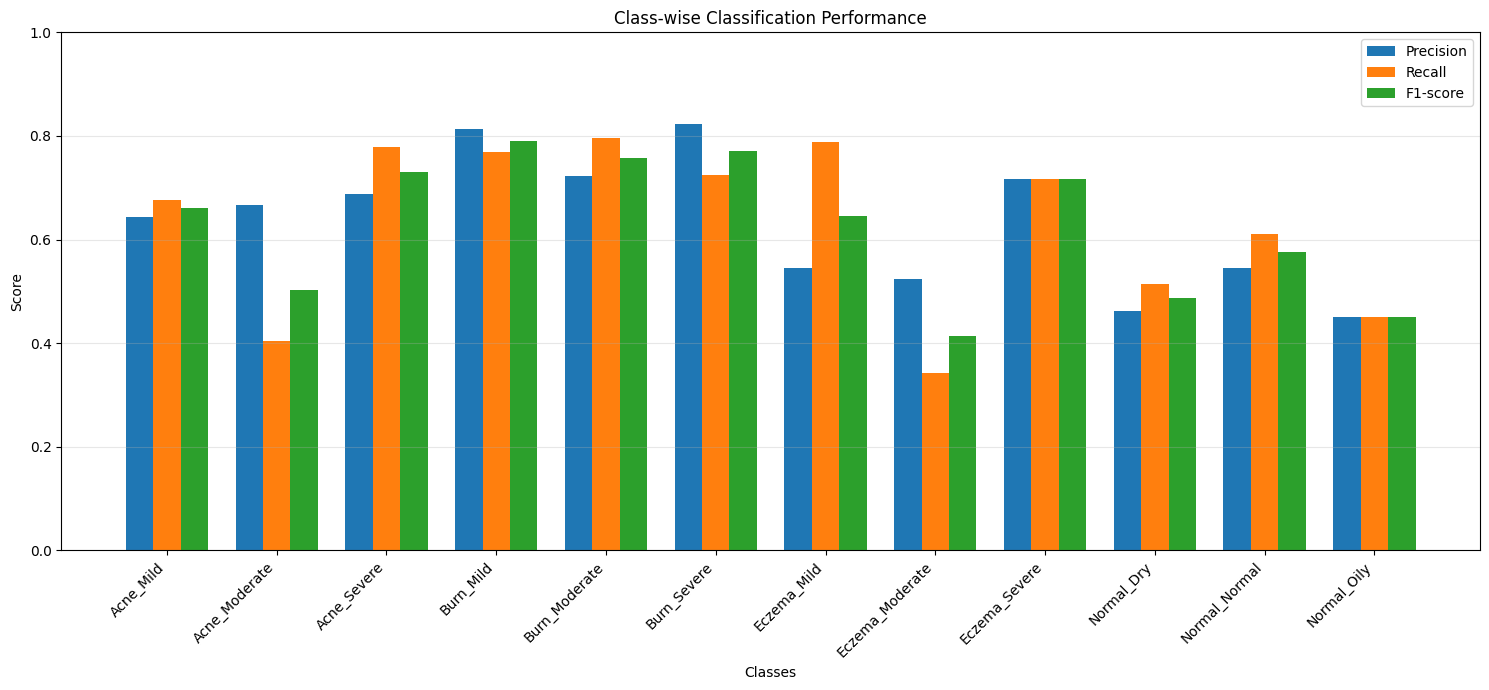

In [34]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ['precision', 'recall', 'f1-score']

report = classification_report(
    true_labels,
    predicted_labels,
    target_names=CLASS_NAMES,
    output_dict=True
)

classes = CLASS_NAMES

precision = [report[c]['precision'] for c in classes]
recall = [report[c]['recall'] for c in classes]
f1 = [report[c]['f1-score'] for c in classes]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(15, 7))

plt.bar(x - width, precision, width, label='Precision')
plt.bar(x, recall, width, label='Recall')
plt.bar(x + width, f1, width, label='F1-score')

plt.xticks(x, classes, rotation=45, ha='right')
plt.ylabel('Score')
plt.xlabel('Classes')
plt.title('Class-wise Classification Performance')

plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.savefig(
    f'{PROJECT_DIR}/results/classwise_performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [35]:
# ============================================================
# Confusion Matrix
# ============================================================

cm = confusion_matrix(

    true_labels,

    predicted_labels

)

cm_df = pd.DataFrame(

    cm,

    index=CLASS_NAMES,

    columns=CLASS_NAMES

)

display(cm_df)

,Acne_Mild,Acne_Moderate,Acne_Severe,Burn_Mild,Burn_Moderate,Burn_Severe,Eczema_Mild,Eczema_Moderate,Eczema_Severe,Normal_Dry,Normal_Normal,Normal_Oily
Acne_Mild,67,7,3,1,0,0,13,1,1,3,1,2
Acne_Moderate,22,40,28,0,0,0,4,1,1,0,2,1
Acne_Severe,5,10,77,1,0,0,1,3,1,0,1,0
Burn_Mild,2,0,0,113,30,1,0,0,0,1,0,0
Burn_Moderate,1,0,0,18,109,7,0,0,2,0,0,0
Burn_Severe,0,0,0,2,10,37,0,0,0,1,1,0
Eczema_Mild,4,0,0,1,0,0,78,12,4,0,0,0
Eczema_Moderate,2,1,2,1,0,0,40,34,19,0,0,0
Eczema_Severe,0,2,2,2,2,0,7,13,71,0,0,0
Normal_Dry,0,0,0,0,0,0,0,0,0,18,12,5


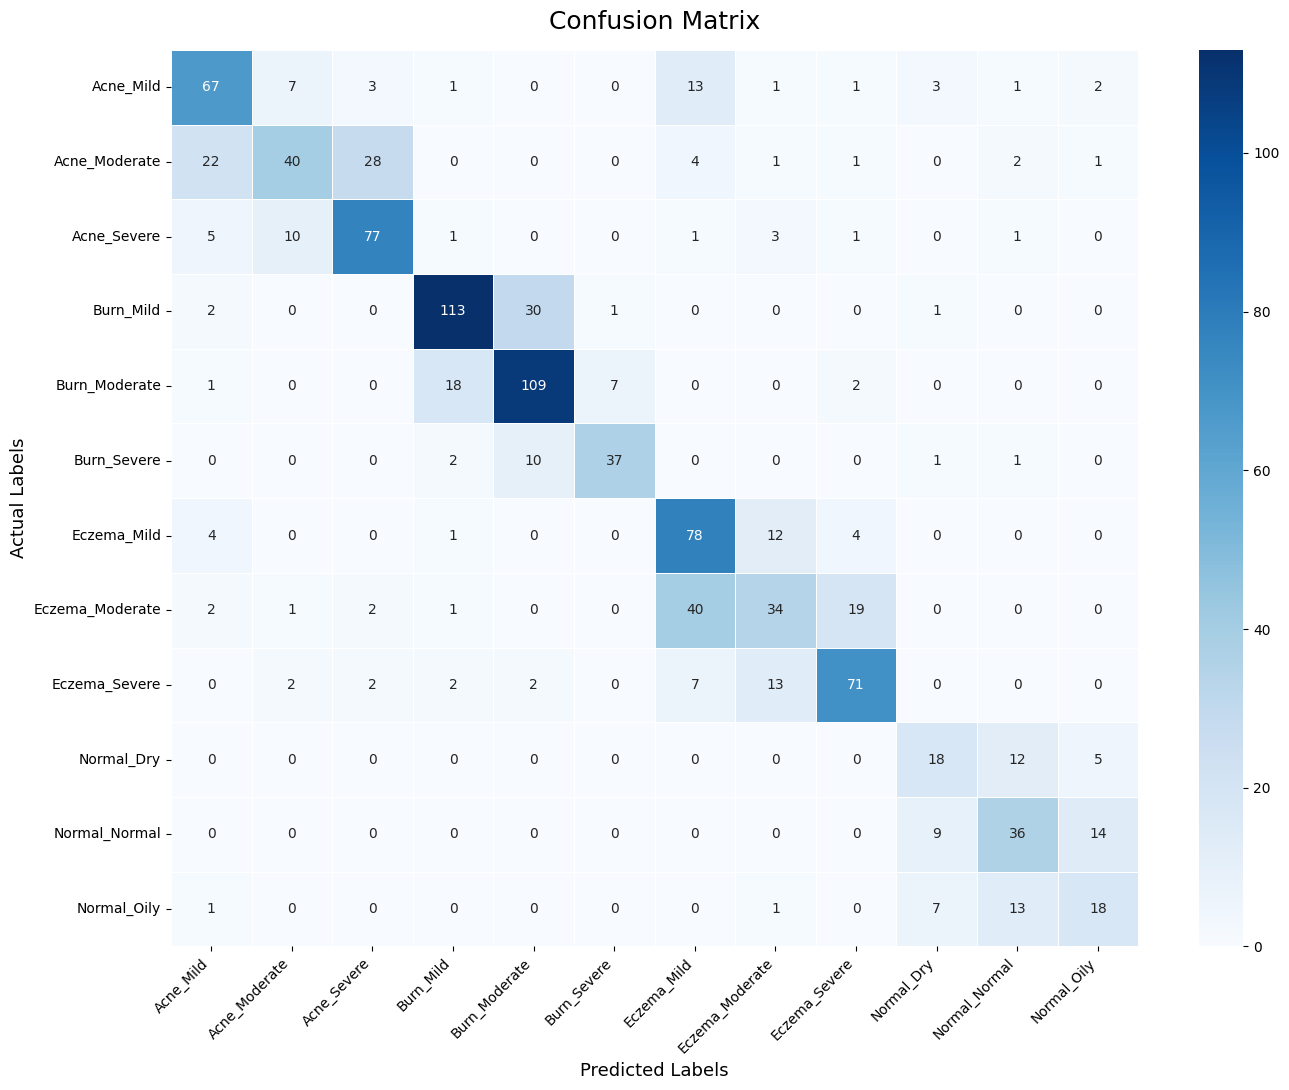

,Acne_Mild,Acne_Moderate,Acne_Severe,Burn_Mild,Burn_Moderate,Burn_Severe,Eczema_Mild,Eczema_Moderate,Eczema_Severe,Normal_Dry,Normal_Normal,Normal_Oily
Acne_Mild,67,7,3,1,0,0,13,1,1,3,1,2
Acne_Moderate,22,40,28,0,0,0,4,1,1,0,2,1
Acne_Severe,5,10,77,1,0,0,1,3,1,0,1,0
Burn_Mild,2,0,0,113,30,1,0,0,0,1,0,0
Burn_Moderate,1,0,0,18,109,7,0,0,2,0,0,0
Burn_Severe,0,0,0,2,10,37,0,0,0,1,1,0
Eczema_Mild,4,0,0,1,0,0,78,12,4,0,0,0
Eczema_Moderate,2,1,2,1,0,0,40,34,19,0,0,0
Eczema_Severe,0,2,2,2,2,0,7,13,71,0,0,0
Normal_Dry,0,0,0,0,0,0,0,0,0,18,12,5


In [36]:
# ============================================================
# Confusion Matrix Visualization
# ============================================================

# Plot confusion matrix
plt.figure(figsize=(14, 11))

sns.heatmap(
    cm_df,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.5,
    linecolor='white',
    cbar=True
)

plt.title('Confusion Matrix', fontsize=18, pad=15)
plt.xlabel('Predicted Labels', fontsize=13)
plt.ylabel('Actual Labels', fontsize=13)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    f'{PROJECT_DIR}/results/confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# Display numerical confusion matrix
display(cm_df)

In [37]:
# ============================================================
# Final Summary
# ============================================================

print("=" * 70)

print("FINAL EVALUATION")

print("=" * 70)

print(f"Total Test Images : {len(test_df)}")

print(f"Total Classes     : {NUM_CLASSES}")

print()

print(f"Accuracy          : {accuracy:.4f}")

print(f"Precision         : {precision:.4f}")

print(f"Recall            : {recall:.4f}")

print(f"F1 Score          : {f1:.4f}")

print("=" * 70)

FINAL EVALUATION
Total Test Images : 1063
Total Classes     : 12

Accuracy          : 0.6566


TypeError: unsupported format string passed to list.__format__